Inainte sa trimiti notebook-ul:

* asigura-te ca totul se executa cum trebuie. Prima oara, **restarteaza kernel-ul** (in meniu, selecteaza Kernel$\rightarrow$Restart & Run all);

* nu lasa niciun mesaj la output (`disp`, `printf`, linii care nu sunt incheiate cu `;`) in functiile pe care le scrii decat daca ti se specifica explicit sa faci acest lucru! Orice abatere va fi **depunctata automat** de grader;

* citeste instructiunile de [aici](https://github.com/radusqrt/numerical-methods/blob/master/lab_instructions.md) cu atentie;

* asigura-te ca rezolvi toate celulele in care scrie `YOUR CODE HERE` sau `YOUR ANSWER HERE` si ca iti treci numele mai jos:

In [11]:
STUDENT_NAME = "Dimitrie David";

---

# Laborator 10: DFT si FFT
### Autor: Radu Stochitoiu

## Problema 1

Implementati funcția ```create_fourier_matrix(N)``` ce primește $N$, numărul de sample-uri, și returnează matricea F pentru DFT.

In [15]:
function [F] = create_fourier_matrix(N)
    F = zeros(N);
    for k = 0 : N - 1
        for l = 0 : N - 1
            F(k + 1, l + 1) = cos((2 * pi * k * l) / N) + 1i * sin((2 * pi * k * l) / N);
        endfor
    endfor
endfunction

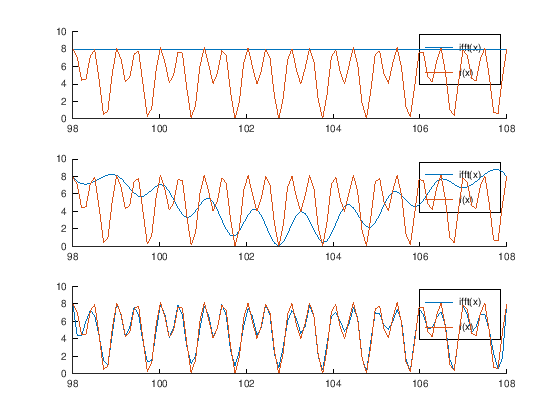

In [16]:
function [y] = f(t)
    y = 5 + 2 * cos(2 * pi * t - pi/2) + 3 * cos(4 * pi * t);
endfunction

% Test 1
N = 5;
ref = dlmread("create_fourier_matrix_5.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 1);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 2
N = 20;
ref = dlmread("create_fourier_matrix_20.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 2);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 3
N = 50;
ref = dlmread("create_fourier_matrix_50.dat");
F = create_fourier_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 3);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

## Problema 2

Implementati funcția ```create_fft_matrix(N)``` ce primește $N$, numărul de sample-uri, și returnează matricea F pentru DFT construită cu ajutorul FFT.

In [31]:
function [F] = create_fft_matrix(N)
    w = exp(2 * pi * 1i / N);
    M = N / 2;
    F_M = create_fourier_matrix(M);
    I_M = eye(M);
    D_M = diag(w .^ ([0 : M - 1]));
    P = zeros(N);
    P(sub2ind(size(P), [1 : N], [1 : 2 : N, 2 : 2 : N])) = 1;
    F = [I_M, D_M; I_M, -D_M] * blkdiag(F_M, F_M) * P;
endfunction

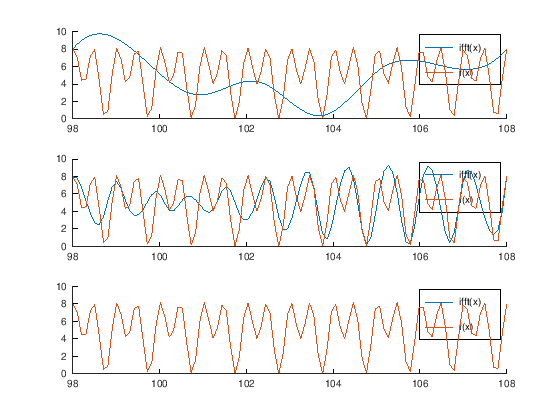

In [32]:
function [y] = f(t)
    y = 5 + 2 * cos(2 * pi * t - pi/2) + 3 * cos(4 * pi * t);
endfunction

% Test 1
N = 8;
ref = dlmread("create_fft_matrix_8.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 1);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 2
N = 32;
ref = dlmread("create_fft_matrix_32.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 2);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");

% Test 3
N = 256;
ref = dlmread("create_fft_matrix_256.dat");
F = create_fft_matrix(N);
assert(norm(F - ref) < 1e-4);
samples = linspace(98, 108, N);
xx = linspace(min(samples), max(samples));

X = inv(F) * f(samples)';
yy = ifft(X) * N;

subplot(3, 1, 3);
hold
plot(xx, interp1(samples, yy, xx, 'spline'));
plot(xx, f(xx));
legend("ifft(x)", "f(x)");